## Example 6: Antithetic Integral Controller — an Ergodic Benchmark

A 3-species network ($X_\ell$ = regulated species, $Z_1$, $Z_2$ = controller species) built from an
**antithetic integral controller (AIC)** acting on a birth–death process. Under the condition below, the
stochastic network has a unique stationary distribution (it is ergodic), so a **single long trajectory**
samples the stationary regime. This makes it a useful benchmark for inference from one long ergodic
trajectory, in contrast to Example 4 (predator–prey), where the trajectory ends in extinction.

**True reactions:**

$$
\begin{aligned}
\varnothing &\xrightarrow{k} X_\ell && \text{(constitutive production)}\\
X_\ell &\xrightarrow{\gamma} \varnothing && \text{(degradation)}\\
Z_1 &\xrightarrow{k_p} Z_1+X_\ell && \text{(actuation: } Z_1 \text{ catalyses production of } X_\ell)\\
\varnothing &\xrightarrow{\mu} Z_1 && \text{(reference)}\\
X_\ell &\xrightarrow{\theta} X_\ell+Z_2 && \text{(sensing: } X_\ell \text{ catalyses production of } Z_2)\\
Z_1+Z_2 &\xrightarrow{\eta} \varnothing && \text{(antithetic annihilation)}
\end{aligned}
$$

**Mass-action propensities:**
$a_1 = k,\quad a_2 = \gamma X_\ell,\quad a_3 = k_p Z_1,\quad a_4 = \mu,\quad a_5 = \theta X_\ell,\quad a_6 = \eta Z_1 Z_2.$

**Stoichiometric changes** $(\Delta X_\ell, \Delta Z_1, \Delta Z_2)$:

| Reaction | $\Delta X_\ell$ | $\Delta Z_1$ | $\Delta Z_2$ |
|---|---|---|---|
| $R_1:\ \varnothing \to X_\ell$ | +1 | 0 | 0 |
| $R_2:\ X_\ell \to \varnothing$ | −1 | 0 | 0 |
| $R_3:\ Z_1 \to Z_1 + X_\ell$ | +1 | 0 | 0 |
| $R_4:\ \varnothing \to Z_1$ | 0 | +1 | 0 |
| $R_5:\ X_\ell \to X_\ell + Z_2$ | 0 | 0 | +1 |
| $R_6:\ Z_1 + Z_2 \to \varnothing$ | 0 | −1 | −1 |

Note that $R_1$ and $R_3$ have the **same** stoichiometric change $(+1,0,0)$. From the trajectory alone the two
cannot be separated event by event; the inference must distinguish them through how the rate of $(+1,0,0)$ jumps
depends on $Z_1$. This makes the example a harder test than Example 4, where every true reaction is the only
active reaction in its channel.

---

### Parameters and the set-point condition

$$
k = 2,\quad \gamma = 1,\quad k_p = 1,\quad \mu = 6,\quad \theta = 2,\quad \eta = 1.
$$

We require

$$
\boxed{\frac{\mu}{\theta} > \frac{k}{\gamma}}
\qquad\left(\text{here } \frac{\mu}{\theta} = 3 > 2 = \frac{k}{\gamma}\right).
$$

Without control ($Z_1 \equiv 0$), $X_\ell$ is a birth–death process with stationary mean $k/\gamma$. The controller
can only *add* production of $X_\ell$, so it can only drive the mean of $X_\ell$ to a set point $\mu/\theta$ above
$k/\gamma$. For this network (unimolecular open-loop network, actuation through $Z_1$, sensing of $X_\ell$), this is
the set-point accessibility condition of Briat, Gupta & Khammash, *Antithetic integral feedback ensures robust
perfect adaptation in noisy biomolecular networks*, Cell Systems 2 (2016) 15–26, Theorem 2; the other conditions
of that theorem (stability and output controllability of the open-loop network) hold here, and the result holds
for any $k_p, \eta > 0$. **This is not true for arbitrary positive parameters:** if $\mu/\theta \le k/\gamma$ the
set point cannot be reached and the process is not ergodic ($Z_2$ grows without bound).

### Stationary identities used as numerical checks

From $\frac{d}{dt}E[Z_1 - Z_2] = \mu - \theta\,E[X_\ell]$ (the $R_6$ events remove one $Z_1$ and one $Z_2$ together and cancel):

$$
E_\pi[X_\ell] = \frac{\mu}{\theta} = 3.
$$

From the $X_\ell$ balance $\frac{d}{dt}E[X_\ell] = k + k_p E[Z_1] - \gamma E[X_\ell]$:

$$
E_\pi[Z_1] = \frac{\gamma(\mu/\theta) - k}{k_p} = 1.
$$

From the $Z_1$ balance $\frac{d}{dt}E[Z_1] = \mu - \eta E[Z_1 Z_2]$:

$$
E_\pi[Z_1 Z_2] = \frac{\mu}{\eta} = 6.
$$

(The stationary mean of $Z_2$ alone is not fixed by these first-moment identities.)

**Computing the empirical means.** Stationary means must be **time averages**, weighting each visited state by
how long the trajectory stays there:
$\bar{X} = \frac{1}{T - t_0}\int_{t_0}^{T} X(t)\,dt$. A plain average over the states recorded at each event is
biased, because states with larger total propensity are left sooner and are recorded more often per unit time.


In [1]:
import sys
import os
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))

from src.parsing import *
from src.inference import *
from src.mcmc import *
from CRN_Simulation.CRN import CRN


### Candidate reaction library

All complexes of order $\le 2$ in the three species give 10 complexes and $10 \times 9 = 90$ candidate reactions.
Every candidate reaction is assigned to the stoichiometric channel $\Delta X$ it produces. Below we print the
channels that contain one of the true reactions.

In [2]:
# Define species names
species_names = ["X", "Z1", "Z2"]

# Define complexes — dimension is (# species) x (# complexes)
# Columns: ∅  X  Z1  Z2  2X  2Z1  2Z2  X+Z1  X+Z2  Z1+Z2
complexes = np.array([
    [0, 1, 0, 0, 2, 0, 0, 1, 1, 0],   # X
    [0, 0, 1, 0, 0, 2, 0, 1, 0, 1],   # Z1
    [0, 0, 0, 1, 0, 0, 2, 0, 1, 1],   # Z2
])

reactant_matrix, product_matrix, stoichiometric_matrix, reaction_names, parameter_names, unique_changes, compatible_reactions = generate_reactions(complexes, species_names)

print(f"Total reactions generated: {len(reaction_names)}")
print(f"Unique stoichiometric changes: {len(unique_changes)}")


Total reactions generated: 90
Unique stoichiometric changes: 54


### Network and parameters

In [3]:
# Hand-specified antithetic integral controller and true rates
#                  R1            R2            R3             R4             R5            R6
reactions_sys = ["Empty_to_X", "X_to_Empty", "Z1_to_X+Z1", "Empty_to_Z1", "X_to_X+Z2", "Z1+Z2_to_Empty"]

k, gamma, kp, mu, theta, eta = 2.0, 1.0, 1.0, 6.0, 2.0, 1.0
rates_sys = [k, gamma, kp, mu, theta, eta]

# Set-point accessibility condition (see the markdown above)
print(f"k/gamma = {k/gamma},  mu/theta = {mu/theta}")
assert mu/theta > k/gamma, "Set point mu/theta must exceed k/gamma for this example to be ergodic"

(CRN_stoichiometric_matrix, CRN_reaction_names, CRN_parameter_names,
 CRN_propensities, trueTheta, parameter_values, sampled_indices) = build_CRN_byNameSelection(
    reactant_matrix, product_matrix, stoichiometric_matrix,
    reaction_names, parameter_names, species_names,
    selected_names=reactions_sys,
    rates=rates_sys,
    verbose=True
)

reactionNetwork = CRN(
    species_names=species_names,
    stoichiometric_matrix=CRN_stoichiometric_matrix,
    parameters_names=CRN_parameter_names,
    reaction_names=CRN_reaction_names,
    propensities=CRN_propensities
)

# Candidate reactions in each channel that contains a true reaction
print("\nChannels containing a true reaction:")
for deltaX in unique_changes:
    rxn_indices = compatible_reactions[deltaX]
    if np.all(trueTheta[rxn_indices] == 0):
        continue
    deltaX_clean = tuple(int(x) for x in deltaX)
    cands = [f"{reaction_names[i].rstrip(':')} ({trueTheta[i]:g})" for i in rxn_indices]
    print(f"ΔX = {deltaX_clean}  →  {cands}")

# Save network for analysis
os.makedirs("../data", exist_ok=True)
save_reaction_network(
    species_names, reactant_matrix,
    CRN_stoichiometric_matrix, CRN_reaction_names, CRN_parameter_names,
    trueTheta, parameter_values, sampled_indices,
    unique_changes, compatible_reactions,
    filename="../data/example6_network.json"
)
print("Network saved to ../data/example6_network.json")


k/gamma = 2.0,  mu/theta = 3.0

Selected CRN Reactions:
Index  Parameter Reaction Name                  Value     
------------------------------------------------------------
0      k0       Empty_to_X:                    2.0000    
9      k9       X_to_Empty:                    1.0000    
24     k24      Z1_to_X+Z1:                    1.0000    
1      k1       Empty_to_Z1:                   6.0000    
16     k16      X_to_X+Z2:                     2.0000    
81     k81      Z1+Z2_to_Empty:                1.0000    

Full trueTheta vector: [2. 6. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 2. 0. 0. 0. 0. 0. 0. 0.
 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]


Channels containing a true reaction:
ΔX = (1, 0, 0)  →  ['Empty_to_X (2)', 'X_to_2X (0)', 'Z1_to_X+Z1 (1)', 'Z2_to_X+Z2 (0)']
ΔX = (0, 1, 0)  →  ['Empty_to_Z1 (6)', 'X_to_X+Z1

### Simulate one long trajectory

Exact SSA from the empty state $(X_\ell, Z_1, Z_2) = (0,0,0)$ up to $T = 5000$. With these rates there are about
24 reactions per unit time, so the trajectory has roughly $1.2 \times 10^5$ events.

Initial state: {'X': np.int64(0), 'Z1': np.int64(0), 'Z2': np.int64(0)}


Trajectory saved to ../data/example6_trajectory.json
Total events: 119910


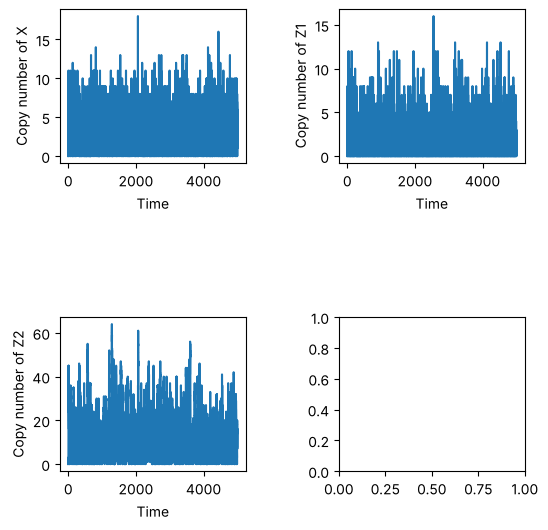

In [4]:
data_dir = "../data"
os.makedirs(data_dir, exist_ok=True)

T_final = 5000

time_list, state_list = generate_single_trajectory(
    reactionNetwork,
    parameter_values,
    species_names,
    finalTime=T_final,
    minVal=[0, 0, 0],
    maxVal=[0, 0, 0],
    seed=42
)

trajectory_file = os.path.join(data_dir, "example6_trajectory.json")
save_trajectory(time_list, state_list, filename=trajectory_file)
print(f"Total events: {len(time_list) - 1}")


### Trajectories of $X_\ell$, $Z_1$, $Z_2$

Full trajectory (top) and a window of 100 time units (bottom). Dashed lines are the stationary means
$E_\pi[X_\ell] = 3$ and $E_\pi[Z_1] = 1$.

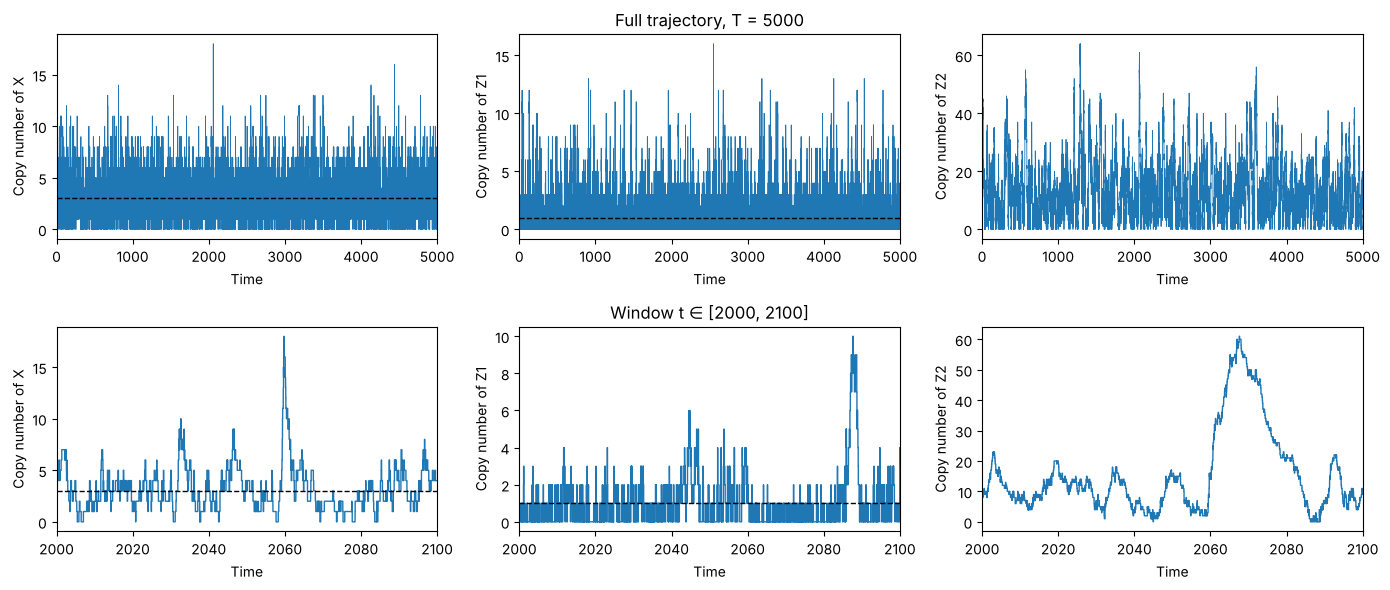

In [5]:
time_list, state_list = load_trajectory(trajectory_file)
t = np.asarray(time_list)
S = np.asarray(state_list)

results_dir = "../results/example6"
os.makedirs(results_dir, exist_ok=True)

reference = {"X": mu/theta, "Z1": (gamma*(mu/theta) - k)/kp, "Z2": None}
window = (2000, 2100)

fig, axs = plt.subplots(2, 3, figsize=(14, 6))
for j, name in enumerate(species_names):
    for row, (t0, t1) in enumerate([(0, T_final), window]):
        ax = axs[row, j]
        m = (t >= t0) & (t <= t1)
        ax.step(t[m], S[m, j], where="post", linewidth=0.6 if row == 0 else 1.0)
        if reference[name] is not None:
            ax.axhline(reference[name], color="k", linestyle="--", linewidth=1)
        ax.set_xlim(t0, t1)
        ax.set_xlabel("Time")
        ax.set_ylabel(f"Copy number of {name}")
axs[0, 1].set_title(f"Full trajectory, T = {T_final}")
axs[1, 1].set_title(f"Window t ∈ [{window[0]}, {window[1]}]")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "example6_trajectory.png"), dpi=150)
plt.show()


### Stationary means: simulation vs. theory

Time averages after a burn-in of $t_0 = 100$. The uncertainty is a batch-means standard error (20 equal time
batches), which accounts for the strong autocorrelation of the integral controller. The last column shows the
(biased) plain average over recorded states for comparison.

In [6]:
burn_in_time = 100
n_batches    = 20

# Holding time of each recorded state (the last state is held until T_final)
tau = np.diff(np.append(t, T_final))

def time_average(values, t0, t1):
    """Time-weighted average of a piecewise-constant path over [t0, t1)."""
    start = np.clip(t, t0, t1)
    end   = np.clip(t + tau, t0, t1)
    w = end - start
    return np.sum(values * w) / np.sum(w)

quantities = {
    "E[X]":     (S[:, 0],           mu/theta),
    "E[Z1]":    (S[:, 1],           (gamma*(mu/theta) - k)/kp),
    "E[Z1*Z2]": (S[:, 1] * S[:, 2], mu/eta),
    "E[Z2]":    (S[:, 2],           np.nan),
}

edges = np.linspace(burn_in_time, T_final, n_batches + 1)
rows = []
for label, (vals, theory) in quantities.items():
    mean    = time_average(vals, burn_in_time, T_final)
    batches = [time_average(vals, a, b) for a, b in zip(edges[:-1], edges[1:])]
    se      = np.std(batches, ddof=1) / np.sqrt(n_batches)
    naive   = vals[t >= burn_in_time].mean()
    rows.append({"quantity": label, "theory": theory, "time average": mean,
                 "batch-means SE": se, "(time avg - theory)/SE": (mean - theory)/se,
                 "per-event average (biased)": naive})

stationary_table = pd.DataFrame(rows).set_index("quantity")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(f"Burn-in t0 = {burn_in_time},  averaging window = {T_final - burn_in_time} time units\n")
print(stationary_table.to_string())


Burn-in t0 = 100,  averaging window = 4900 time units

          theory  time average  batch-means SE  (time avg - theory)/SE  per-event average (biased)
quantity                                                                                          
E[X]      3.0000        2.9946          0.0328                 -0.1645                      3.5232
E[Z1]     1.0000        1.0039          0.0430                  0.0915                      1.4283
E[Z1*Z2]  6.0000        5.9490          0.0509                 -1.0027                      9.8781
E[Z2]        NaN       13.2835          0.5571                     NaN                     12.7983


### Running time average

$\frac{1}{t - t_0}\int_{t_0}^{t} X_\ell(s)\,ds$ and the same for $Z_1$, approaching $\mu/\theta = 3$ and $1$.

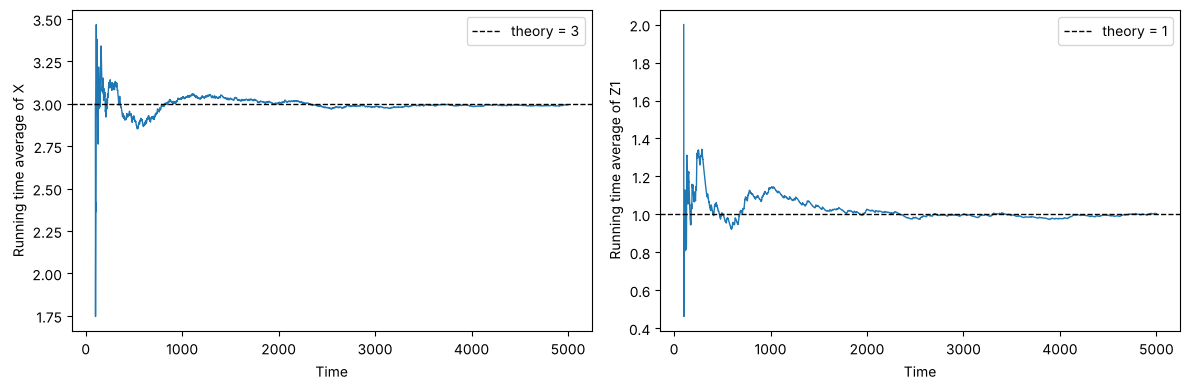

In [7]:
m = t >= burn_in_time
dt_m = np.diff(np.append(t[m], T_final))
cum_time = np.cumsum(dt_m)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, j, name in [(axs[0], 0, "X"), (axs[1], 1, "Z1")]:
    running = np.cumsum(S[m, j] * dt_m) / cum_time
    ax.plot(t[m] + dt_m, running, linewidth=1)
    ax.axhline(reference[name], color="k", linestyle="--", linewidth=1,
               label=f"theory = {reference[name]:g}")
    ax.set_xlabel("Time")
    ax.set_ylabel(f"Running time average of {name}")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "example6_running_mean.png"), dpi=150)
plt.show()


### Parse the trajectory

The whole trajectory (including the initial transient) is used for inference: the likelihood of an exact
trajectory is valid from any initial state, so no burn-in is needed here.

In [8]:
print("Parsing trajectory...")
unique_states, jump_counts, waiting_times, propensities = parse_trajectory(
    state_list, time_list, reactant_matrix, unique_changes, compatible_reactions, verbose=True)

print(f"\n{len(unique_states)} unique states observed")


Parsing trajectory...
Tracking 54 unique stoichiometric changes.
Trajectory length: 119911 timepoints. Iterating to len-2 to avoid final non-jump.


Finished parsing trajectory. Observed 2881 unique states.

2881 unique states observed


### Bayesian inference (adaptive MCMC, spike-and-slab prior)

Settings shared by all examples: spike-and-slab prior with spike weight $\pi = 0.75$ and Gamma slab (shape 2,
rate 0.25); adaptive Metropolis–Hastings with 500,000 iterations per channel, burn-in 50,000, thinning 100
(4,501 retained draws), initial rates uniform on $[0.001, 2]$, proposal covariance adapted every 10 iterations after burn-in and
estimated from the states after iteration 25,000 (so the initial transient does not inflate it).
MCMC is run for every stoichiometric channel with at least one observed event (the decision never uses the true
rates). Each channel has its own seeded random streams, so results are reproducible.

`run_channel_mcmc` (in `src/mcmc.py`) writes, per channel, the chain (`..._chain.npz`, every 10th iteration),
the plots, and one row per candidate reaction in `mcmc_summary.xlsx` (posterior mean, 95% interval, Pr(off),
effective sample size of the retained draws, acceptance rate, seed).

In [9]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # 0/0 in diagnostics of switched-off reactions (constant chains)

results_dir = "../results/example6"
SEED = 6     # base seed of this example: channel i uses the random streams (SEED, i, 0) and (SEED, i, 1)

# MCMC settings: the same for every example in the manuscript
NIterates = 500_000
Burnin    = 50_000
Thinout   = 100

os.makedirs(results_dir, exist_ok=True)
summary_file = os.path.join(results_dir, "mcmc_summary.xlsx")
if os.path.exists(summary_file):
    os.remove(summary_file)      # summarize_chains appends, so start from a fresh file

for index, deltaX in enumerate(unique_changes):
    (local_counts, local_waiting_times, local_propensities, selected_deltaX) = extract_local_data(
        jump_counts, waiting_times, propensities, unique_changes, index=index, deltaX=deltaX, verbose=False)
    total_count = sum(local_counts.values())
    if total_count == 0:
        continue                 # MCMC is run for every channel with at least one observed event
    localTheta = trueTheta[compatible_reactions[selected_deltaX]]   # used only for plots and the summary
    names = [reaction_names[i] for i in compatible_reactions[selected_deltaX]]
    print(f"Index {index}, change {tuple(int(x) for x in deltaX)}: {total_count} events, candidates {names}")
    run_channel_mcmc(local_counts, local_waiting_times, local_propensities, localTheta, trueTheta,
                     results_dir=results_dir, index=index, total_count=total_count, seed=SEED,
                     NIterates=NIterates, Burnin=Burnin, Thinout=Thinout)


✅ All states processed successfully — no empty propensities, consistent lengths, no negative counts, all waiting times valid.
Index 0, change (1, 0, 0): 15010 events, candidates ['Empty_to_X:', 'X_to_2X:', 'Z1_to_X+Z1:', 'Z2_to_X+Z2:']


Estimated Theta: [2.03662566 0.         0.95791275 0.        ]
Estimated Error: [0.03662566 0.         0.04208725 0.        ]


Plot saved to ../results/example6/AdaptiveMCMC_plot_Index_0_TotalCount_15010_kde.png


Plot saved to ../results/example6/AdaptiveMCMC_plot_Index_0_TotalCount_15010_posterior.png
Run 0 | Adaptive Spike & Slab: L2 error of mean from true theta = 0.05579
Saving summary to: ../results/example6/mcmc_summary.xlsx
Summary saved successfully.
✅ All states processed successfully — no empty propensities, consistent lengths, no negative counts, all waiting times valid.
Index 1, change (0, 1, 0): 29959 events, candidates ['Empty_to_Z1:', 'X_to_X+Z1:', 'Z1_to_2Z1:', 'Z2_to_Z1+Z2:']


Estimated Theta: [5.991415 0.       0.       0.      ]
Estimated Error: [0.008585 0.       0.       0.      ]


Plot saved to ../results/example6/AdaptiveMCMC_plot_Index_1_TotalCount_29959_kde.png


... (8 outputs left out)

✅ All states processed successfully — no empty propensities, consistent lengths, no negative counts, all waiting times valid.
✅ All states processed successfully — no empty propensities, consistent lengths, no negative counts, all waiting times valid.
✅ All states processed successfully — no empty propensities, consistent lengths, no negative counts, all waiting times valid.
✅ All states processed successfully — no empty propensities, consistent lengths, no negative counts, all waiting times valid.
✅ All states processed successfully — no empty propensities, consistent lengths, no negative counts, all waiting times valid.
Index 51, change (0, -1, -1): 29958 events, candidates ['Z1+Z2_to_Empty:']


Estimated Theta: [1.00691119]
Estimated Error: [0.00691119]


Plot saved to ../results/example6/AdaptiveMCMC_plot_Index_51_TotalCount_29958_kde.png


Run 51 | Adaptive Spike & Slab: L2 error of mean from true theta = 0.00691
Saving summary to: ../results/example6/mcmc_summary.xlsx
Summary saved successfully.
✅ All states processed successfully — no empty propensities, consistent lengths, no negative counts, all waiting times valid.
✅ All states processed successfully — no empty propensities, consistent lengths, no negative counts, all waiting times valid.


### Summary: true rates vs. posterior

One row per candidate reaction in each observed channel. $\Pr(\text{off})$ is the posterior probability that the
reaction is absent (rate in the spike at zero).

In [10]:
df = pd.read_excel(summary_file)

rows = []
for _, r in df.iterrows():
    deltaX = unique_changes[int(r["Run_Index"])]
    rxn    = compatible_reactions[deltaX][int(r["Param_Index"])]
    rows.append({
        "ΔX":         tuple(int(x) for x in deltaX),
        "Reaction":   reaction_names[rxn].rstrip(":"),
        "Events":     int(r["Count"]),
        "True rate":  r["True_Theta"],
        "Post. mean": r["Mean"],
        "95% CI":     f"({r['CI_lower']:.3f}, {r['CI_upper']:.3f})",
        "Pr(off)":    r["Prob_Off"],
    })
posterior_table = pd.DataFrame(rows)
print(posterior_table.to_string(index=False))


         ΔX       Reaction  Events  True rate  Post. mean         95% CI  Pr(off)
  (1, 0, 0)     Empty_to_X   15010          2      2.0366 (1.988, 2.087)   0.0000
  (1, 0, 0)        X_to_2X   15010          0      0.0000 (0.000, 0.000)   1.0000
  (1, 0, 0)     Z1_to_X+Z1   15010          1      0.9579 (0.915, 0.999)   0.0000
  (1, 0, 0)     Z2_to_X+Z2   15010          0      0.0000 (0.000, 0.000)   1.0000
  (0, 1, 0)    Empty_to_Z1   29959          6      5.9914 (5.925, 6.059)   0.0000
  (0, 1, 0)      X_to_X+Z1   29959          0      0.0000 (0.000, 0.000)   1.0000
  (0, 1, 0)      Z1_to_2Z1   29959          0      0.0000 (0.000, 0.000)   1.0000
  (0, 1, 0)    Z2_to_Z1+Z2   29959          0      0.0000 (0.000, 0.000)   1.0000
  (0, 0, 1)    Empty_to_Z2   29974          0      0.0000 (0.000, 0.000)   1.0000
  (0, 0, 1)      X_to_X+Z2   29974          2      1.9986 (1.976, 2.022)   0.0000
  (0, 0, 1)    Z1_to_Z1+Z2   29974          0      0.0000 (0.000, 0.000)   1.0000
  (0, 0, 1)     

### Next

* `example6_aic_Tsweep.ipynb` repeats this inference on prefixes of the same trajectory ($T = 100, 500, 1000, 5000$)
  to show the posterior concentrating as $T$ grows ($T = 5000$ reproduces this notebook exactly).
* `example6_aic_lasso.ipynb` compares with the LASSO of Zhang et al. (2019) on the same prefixes.